# 01 - Is our digital zoom really an exact camera change?

Everything in the paper rests on one claim: crop a box out of an image, resize it back,
and you get the image a pinhole camera with K' = S (K - shift) would have taken. Depth of
every surviving pixel is unchanged. Before testing any model we check our own code:

1. project random 3D points with K, apply the crop+resize to the pixel coordinates,
   and compare with projecting the same points with `zoom_K(K)`;
2. a constant depth map must come back unchanged from `unzoom_depth`;
3. the blur control keeps the field of view but loses detail.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import zoom

FIG = ROOT / "outputs/figures"
FIG.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(0)

## 1. Projection check
Pixel centres matter here: with `align_corners=False`, pixel u in the crop maps to
(u - x0 + 0.5) * W / cw - 0.5 in the zoomed image, so the exact law has a half-pixel term.
`zoom_K` includes it; the error below should be at floating-point level.

In [2]:
H, W = 352, 1216
K = np.array([[721.5, 0, 596.5], [0, 721.5, 149.9], [0, 0, 1]])


def project(K, P):
    p = (K @ P.T).T
    return p[:, :2] / p[:, 2:]


P = np.stack([rng.uniform(-10, 10, 5000), rng.uniform(-2, 3, 5000), rng.uniform(3, 80, 5000)], 1)
for s in (1.25, 2.0, 3.0):
    for c in ((0.5, 0.5), (0.25, 0.75)):
        box = zoom.zoom_box(H, W, s, *c)
        x0, y0, cw, ch = box
        uv = project(K, P)
        inside = (uv[:, 0] >= x0) & (uv[:, 0] < x0 + cw) & (uv[:, 1] >= y0) & (uv[:, 1] < y0 + ch)
        sx, sy = W / cw, H / ch
        exact = np.stack([(uv[:, 0] - x0 + 0.5) * sx - 0.5, (uv[:, 1] - y0 + 0.5) * sy - 0.5], 1)
        ours = project(zoom.zoom_K(K, box, (H, W)), P)
        err = np.abs(exact - ours)[inside].max()
        print(f"s={s:4}  centre={c}  box={box}  max pixel error of zoom_K: {err:.3f} px")

s=1.25  centre=(0.5, 0.5)  box=(122, 35, 973, 282)  max pixel error of zoom_K: 0.000 px
s=1.25  centre=(0.25, 0.75)  box=(0, 70, 973, 282)  max pixel error of zoom_K: 0.000 px
s= 2.0  centre=(0.5, 0.5)  box=(304, 88, 608, 176)  max pixel error of zoom_K: 0.000 px
s= 2.0  centre=(0.25, 0.75)  box=(0, 176, 608, 176)  max pixel error of zoom_K: 0.000 px
s= 3.0  centre=(0.5, 0.5)  box=(406, 118, 405, 117)  max pixel error of zoom_K: 0.000 px
s= 3.0  centre=(0.25, 0.75)  box=(102, 206, 405, 117)  max pixel error of zoom_K: 0.000 px


## 2. A constant depth map must survive the round trip

In [3]:
for s in (1.25, 2.0, 3.0):
    box = zoom.zoom_box(H, W, s)
    back = zoom.unzoom_depth(np.full((H, W), 7.0, np.float32), box)
    print(f"s={s}: unzoomed shape {back.shape}, crop shape {(box[3], box[2])}, max |d - 7| = {np.abs(back - 7).max():.2e}")

s=1.25: unzoomed shape (282, 973), crop shape (282, 973), max |d - 7| = 0.00e+00
s=2.0: unzoomed shape (176, 608), crop shape (176, 608), max |d - 7| = 0.00e+00
s=3.0: unzoomed shape (117, 405), crop shape (117, 405), max |d - 7| = 0.00e+00


## 3. What the zoom and the blur control look like
A synthetic test card so this notebook needs no downloaded data.

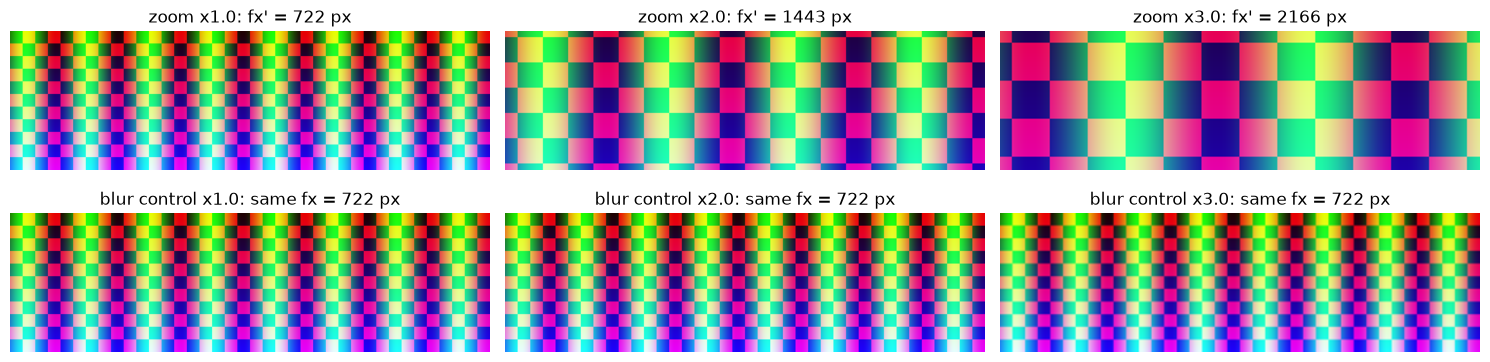

In [4]:
yy, xx = np.mgrid[0:H, 0:W]
card = np.stack([(xx // 32 + yy // 32) % 2 * 200 + 30,
                 (np.sin(xx / 25.0) * 0.5 + 0.5) * 255,
                 (yy / H) * 255], -1).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(15, 4))
for ax, s in zip(axes[0], (1.0, 2.0, 3.0)):
    box = zoom.zoom_box(H, W, s)
    ax.imshow(zoom.zoom_image(card, box) if s > 1 else card)
    ax.set_title(f"zoom x{s}: fx' = {zoom.zoom_K(K, box, (H, W))[0, 0]:.0f} px")
for ax, s in zip(axes[1], (1.0, 2.0, 3.0)):
    ax.imshow(zoom.blur_control(card, s) if s > 1 else card)
    ax.set_title(f"blur control x{s}: same fx = {K[0, 0]:.0f} px")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "01_zoom_and_blur_control.png", dpi=70)
plt.show()